<a href="https://colab.research.google.com/github/rmoy1-clt/Intro-to-ML/blob/main/HW7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW7: Fully Connected Neural Networks for CIFAR-10

## 0. Setup

Same preprocessing and training configuration for every experiment (Lecture 16):

* Images converted to tensors, normalized per channel with the CIFAR-10 mean and standard deviation, and flattened to 3072 values (32 x 32 x 3).
* 5,000 of the 50,000 training images are held out as a **validation set**, so 45,000 images are used for training. The 10,000 test images are only used for the final evaluation.
* Loss: `nn.CrossEntropyLoss`. Optimizer: SGD, learning rate 0.01, batch size 64 (as in the lecture).
* Every network is trained for 100 epochs. The **selected number of epochs** is the epoch with the highest validation accuracy, and the weights from that epoch are the ones evaluated on the test set (early stopping).
* The whole dataset is kept on the GPU and shuffled every epoch, which makes training much faster than a DataLoader.

In [15]:
import time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

N_EPOCHS = 100
LR = 1e-2
BATCH = 64

device: cuda Tesla T4


In [16]:
# CIFAR-10 is downloaded by torchvision into the Colab session
DATA_ROOT = './data'

In [17]:
mean, std = (0.4915, 0.4823, 0.4468), (0.2470, 0.2435, 0.2616)
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
train_full = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=tf)
test_set = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=tf)

def to_tensors(ds):
    X = torch.stack([img for img, _ in ds]).view(len(ds), -1)     # flatten to 3072
    y = torch.tensor([lbl for _, lbl in ds])
    return X, y

X_all, y_all = to_tensors(train_full)
X_test, y_test = to_tensors(test_set)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
X_val, y_val = X_all[perm[:5000]], y_all[perm[:5000]]
X_tr, y_tr = X_all[perm[5000:]], y_all[perm[5000:]]

X_tr, y_tr, X_val, y_val, X_test, y_test = [t.to(device) for t in (X_tr, y_tr, X_val, y_val, X_test, y_test)]
print('train:', tuple(X_tr.shape), ' validation:', tuple(X_val.shape), ' test:', tuple(X_test.shape))
print('classes:', train_full.classes)

train: (45000, 3072)  validation: (5000, 3072)  test: (10000, 3072)
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [18]:
def make_mlp(hidden, act=nn.ReLU):
    """3072 -> hidden[0] -> ... -> hidden[-1] -> 10, with `act` after every hidden layer."""
    layers, prev = [], 3072
    for h in hidden:
        layers += [nn.Linear(prev, h), act()]
        prev = h
    layers.append(nn.Linear(prev, 10))
    return nn.Sequential(*layers)

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y, loss_fn):
    model.eval()
    out = torch.cat([model(X[i:i + 5000]) for i in range(0, len(X), 5000)])
    return loss_fn(out, y).item(), (out.argmax(1) == y).float().mean().item()

def run(name, hidden, act=nn.ReLU):
    """Train for N_EPOCHS, keep the weights with the best validation accuracy, then test them."""
    torch.manual_seed(SEED)
    model = make_mlp(hidden, act).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=LR)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time']}
    best = {'val_acc': -1}
    t0 = time.time()
    for epoch in range(1, N_EPOCHS + 1):
        model.train()
        idx = torch.randperm(len(X_tr), device=device)
        tot_loss, correct = 0.0, 0
        for i in range(0, len(idx), BATCH):
            b = idx[i:i + BATCH]
            out = model(X_tr[b])
            loss = loss_fn(out, y_tr[b])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            tot_loss += loss.item() * len(b)
            correct += (out.argmax(1) == y_tr[b]).sum().item()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        hist['time'].append(time.time() - t0)
        hist['train_loss'].append(tot_loss / len(idx))
        hist['train_acc'].append(correct / len(idx))
        vl, va = evaluate(model, X_val, y_val, loss_fn)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if va > best['val_acc']:
            best = {'val_acc': va, 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
        if epoch == 1 or epoch % 10 == 0:
            print(f'{name} | epoch {epoch:3d} | train loss {hist["train_loss"][-1]:.4f} acc {hist["train_acc"][-1]:.4f}'
                  f' | val loss {vl:.4f} acc {va:.4f} | {hist["time"][-1]:.1f}s')
    model.load_state_dict(best['state'])
    tr_loss, tr_acc = evaluate(model, X_tr, y_tr, loss_fn)
    te_loss, te_acc = evaluate(model, X_test, y_test, loss_fn)
    ep = best['epoch']
    res = {'Hidden layers': str(hidden), 'Activation': act.__name__, 'Parameters': n_params(model),
           'Epochs selected': ep, 'Training time (s)': hist['time'][ep - 1],
           'Time for 100 epochs (s)': hist['time'][-1], 'Training loss': tr_loss, 'Training acc': tr_acc,
           'Validation acc': best['val_acc'], 'Evaluation (test) acc': te_acc}
    print(f'\n{name}: selected epoch {ep}, parameters {res["Parameters"]:,}')
    print(f'  training loss {tr_loss:.4f}, training acc {tr_acc:.4f}, test acc {te_acc:.4f}, '
          f'training time to epoch {ep}: {res["Training time (s)"]:.1f}s')
    return model, hist, res

def plot_hist(hist, res, title):
    ep = range(1, len(hist['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, hist['train_loss'], label='Training'); ax[0].plot(ep, hist['val_loss'], label='Validation')
    ax[0].set_ylabel('Cross-entropy loss'); ax[0].set_title(f'{title}: loss')
    ax[1].plot(ep, hist['train_acc'], label='Training'); ax[1].plot(ep, hist['val_acc'], label='Validation')
    ax[1].set_ylabel('Accuracy'); ax[1].set_title(f'{title}: accuracy')
    for a in ax:
        a.axvline(res['Epochs selected'], color='k', ls=':', label=f'selected epoch ({res["Epochs selected"]})')
        a.set_xlabel('Epoch'); a.grid(alpha=0.3); a.legend()
    plt.tight_layout(); plt.show()

results, histories = {}, {}

---
# Problem 1



1.a | epoch   1 | train loss 1.9060 acc 0.3335 | val loss 1.7227 acc 0.3948 | 1.1s
1.a | epoch  10 | train loss 1.1370 acc 0.6048 | val loss 1.4729 acc 0.4878 | 10.4s
1.a | epoch  20 | train loss 0.7655 acc 0.7390 | val loss 1.9016 acc 0.4800 | 21.6s
1.a | epoch  30 | train loss 0.4687 acc 0.8428 | val loss 3.3967 acc 0.4014 | 32.0s
1.a | epoch  40 | train loss 0.2594 acc 0.9192 | val loss 2.1238 acc 0.5270 | 42.5s
1.a | epoch  50 | train loss 0.1166 acc 0.9687 | val loss 3.9239 acc 0.4476 | 52.9s
1.a | epoch  60 | train loss 0.0399 acc 0.9931 | val loss 2.8079 acc 0.5364 | 63.1s
1.a | epoch  70 | train loss 0.0103 acc 0.9995 | val loss 3.4898 acc 0.5082 | 73.3s
1.a | epoch  80 | train loss 0.0086 acc 0.9997 | val loss 3.0843 acc 0.5468 | 83.7s
1.a | epoch  90 | train loss 0.0044 acc 1.0000 | val loss 3.2439 acc 0.5448 | 94.2s
1.a | epoch 100 | train loss 0.0032 acc 1.0000 | val loss 3.3512 acc 0.5444 | 104.7s

1.a: selected epoch 99, parameters 1,707,274
  training loss 0.0032, traini

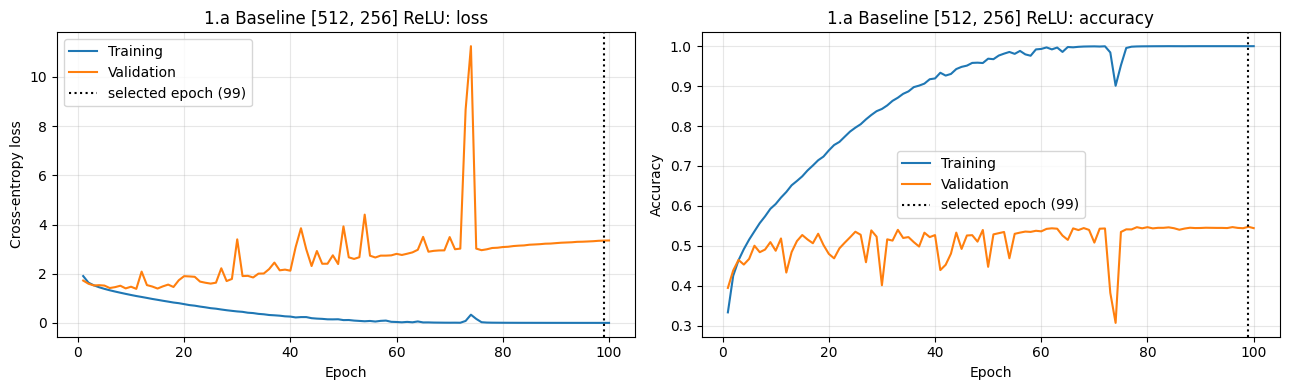

In [19]:
model_1a, histories['1.a Baseline'], results['1.a Baseline'] = run('1.a', [512, 256])
print(model_1a)
plot_hist(histories['1.a Baseline'], results['1.a Baseline'], '1.a Baseline [512, 256] ReLU')

## 1.b Four hidden layers (512, 256, 128, 64) with ReLU
.

1.b | epoch   1 | train loss 2.2339 acc 0.1836 | val loss 2.0893 acc 0.2478 | 1.3s
1.b | epoch  10 | train loss 1.2328 acc 0.5621 | val loss 1.6360 acc 0.4562 | 13.2s
1.b | epoch  20 | train loss 0.8384 acc 0.7035 | val loss 2.1053 acc 0.4436 | 26.1s
1.b | epoch  30 | train loss 0.4921 acc 0.8260 | val loss 2.2697 acc 0.4856 | 39.1s
1.b | epoch  40 | train loss 0.2671 acc 0.9078 | val loss 2.3847 acc 0.5202 | 52.1s
1.b | epoch  50 | train loss 0.1395 acc 0.9528 | val loss 3.1747 acc 0.5040 | 65.1s
1.b | epoch  60 | train loss 0.1297 acc 0.9583 | val loss 3.8728 acc 0.4968 | 78.1s
1.b | epoch  70 | train loss 0.0079 acc 0.9984 | val loss 4.0071 acc 0.5350 | 91.0s
1.b | epoch  80 | train loss 0.0022 acc 0.9998 | val loss 4.3125 acc 0.5430 | 104.0s
1.b | epoch  90 | train loss 0.0006 acc 1.0000 | val loss 4.5206 acc 0.5464 | 117.0s
1.b | epoch 100 | train loss 0.0004 acc 1.0000 | val loss 4.6474 acc 0.5472 | 129.9s

1.b: selected epoch 71, parameters 1,746,506
  training loss 0.0034, trai

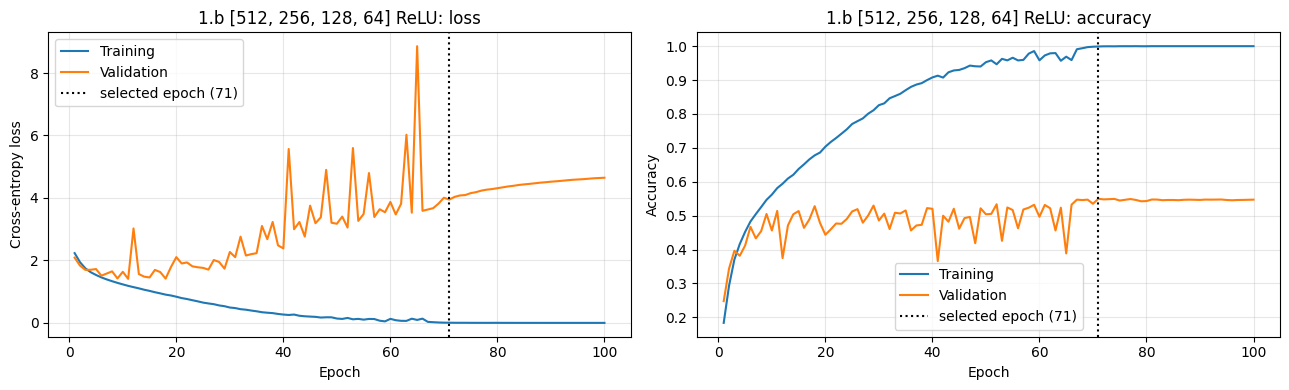

In [20]:
model_1b, histories['1.b 4 layers'], results['1.b 4 layers'] = run('1.b', [512, 256, 128, 64])
print(model_1b)
plot_hist(histories['1.b 4 layers'], results['1.b 4 layers'], '1.b [512, 256, 128, 64] ReLU')

                    Hidden layers Activation Parameters Epochs selected Training time (s) Time for 100 epochs (s) Training loss Training acc Validation acc Evaluation (test) acc
1.a Baseline           [512, 256]       ReLU    1707274              99          103.6403                104.6501        0.0032       1.0000         0.5478                0.5391
1.b 4 layers  [512, 256, 128, 64]       ReLU    1746506              71           92.2853                129.9383        0.0034       0.9997         0.5498                0.5442


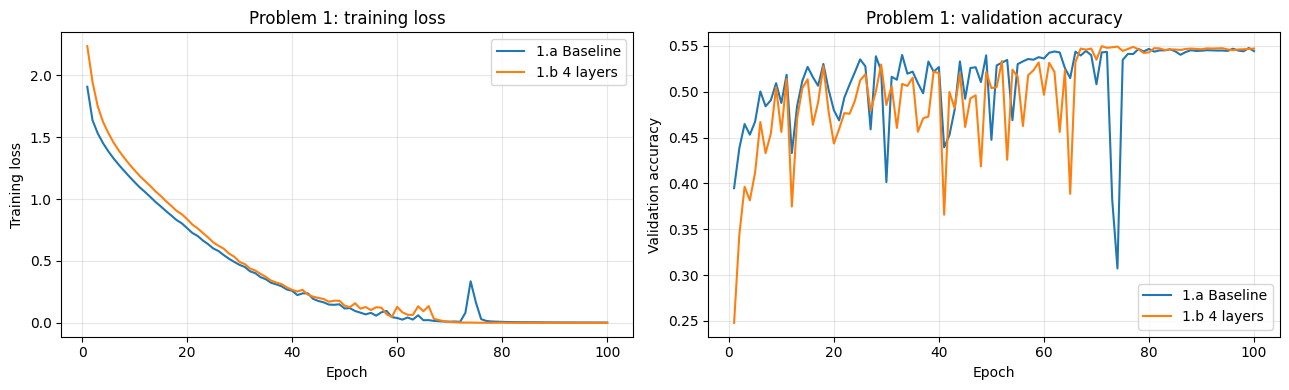

In [21]:
def compare(keys):
    t = pd.DataFrame({k: results[k] for k in keys}).T
    show = t[['Hidden layers', 'Activation', 'Parameters', 'Epochs selected', 'Training time (s)',
              'Time for 100 epochs (s)', 'Training loss', 'Training acc', 'Validation acc', 'Evaluation (test) acc']]
    with pd.option_context('display.width', 250, 'display.max_columns', 20, 'display.float_format', '{:.4f}'.format):
        print(show)

def plot_compare(keys, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for k in keys:
        h = histories[k]
        ep = range(1, len(h['val_acc']) + 1)
        ax[0].plot(ep, h['train_loss'], label=k)
        ax[1].plot(ep, h['val_acc'], label=k)
    ax[0].set_ylabel('Training loss'); ax[0].set_title(f'{title}: training loss')
    ax[1].set_ylabel('Validation accuracy'); ax[1].set_title(f'{title}: validation accuracy')
    for a in ax:
        a.set_xlabel('Epoch'); a.grid(alpha=0.3); a.legend()
    plt.tight_layout(); plt.show()

compare(['1.a Baseline', '1.b 4 layers'])
plot_compare(['1.a Baseline', '1.b 4 layers'], 'Problem 1')

---
# Problem 2


2.a | epoch   1 | train loss 2.3049 acc 0.0996 | val loss 2.3033 acc 0.1034 | 2.0s
2.a | epoch  10 | train loss 2.3026 acc 0.0998 | val loss 2.3027 acc 0.0956 | 20.9s
2.a | epoch  20 | train loss 2.3026 acc 0.1002 | val loss 2.3028 acc 0.0956 | 41.1s
2.a | epoch  30 | train loss 2.3026 acc 0.0989 | val loss 2.3027 acc 0.0956 | 61.7s
2.a | epoch  40 | train loss 2.3025 acc 0.0997 | val loss 2.3026 acc 0.0956 | 82.2s
2.a | epoch  50 | train loss 2.3020 acc 0.1161 | val loss 2.3020 acc 0.0956 | 103.0s
2.a | epoch  60 | train loss 1.9498 acc 0.2000 | val loss 1.9603 acc 0.2158 | 123.7s
2.a | epoch  70 | train loss 1.6496 acc 0.3267 | val loss 2.0368 acc 0.2612 | 144.3s
2.a | epoch  80 | train loss 1.2656 acc 0.4982 | val loss 2.0320 acc 0.3660 | 164.6s
2.a | epoch  90 | train loss 0.8836 acc 0.6458 | val loss 2.9037 acc 0.3914 | 185.2s
2.a | epoch 100 | train loss 0.6288 acc 0.7454 | val loss 2.4336 acc 0.4482 | 205.2s

2.a: selected epoch 97, parameters 1,771,466
  training loss 0.6632, t

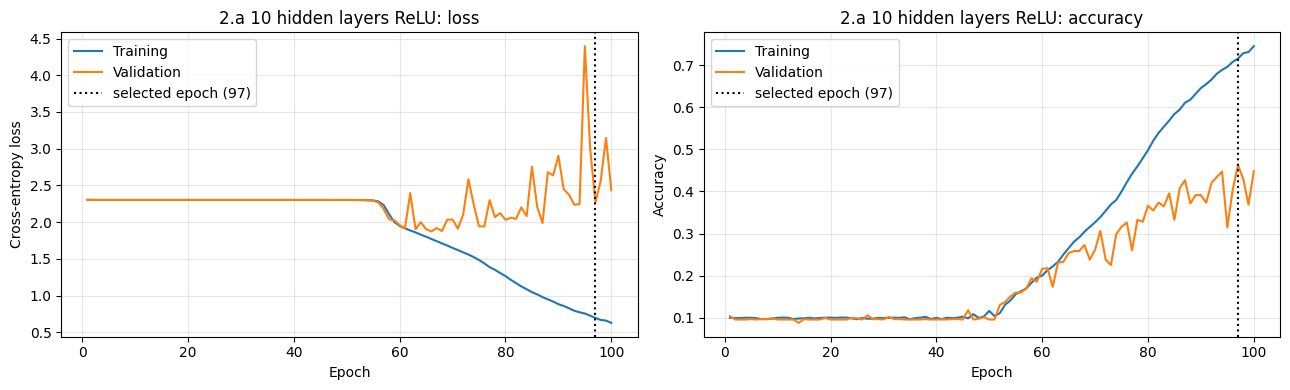

In [22]:
DEEP = [512, 256, 128, 64] + [64] * 6
model_2a, histories['2.a 10 layers'], results['2.a 10 layers'] = run('2.a', DEEP)
print(model_2a)
plot_hist(histories['2.a 10 layers'], results['2.a 10 layers'], '2.a 10 hidden layers ReLU')

                                             Hidden layers Activation Parameters Epochs selected Training time (s) Time for 100 epochs (s) Training loss Training acc Validation acc Evaluation (test) acc
1.b 4 layers                           [512, 256, 128, 64]       ReLU    1746506              71           92.2853                129.9383        0.0034       0.9997         0.5498                0.5442
2.a 10 layers  [512, 256, 128, 64, 64, 64, 64, 64, 64, 64]       ReLU    1771466              97          199.4631                205.2347        0.6632       0.7291         0.4632                0.4537


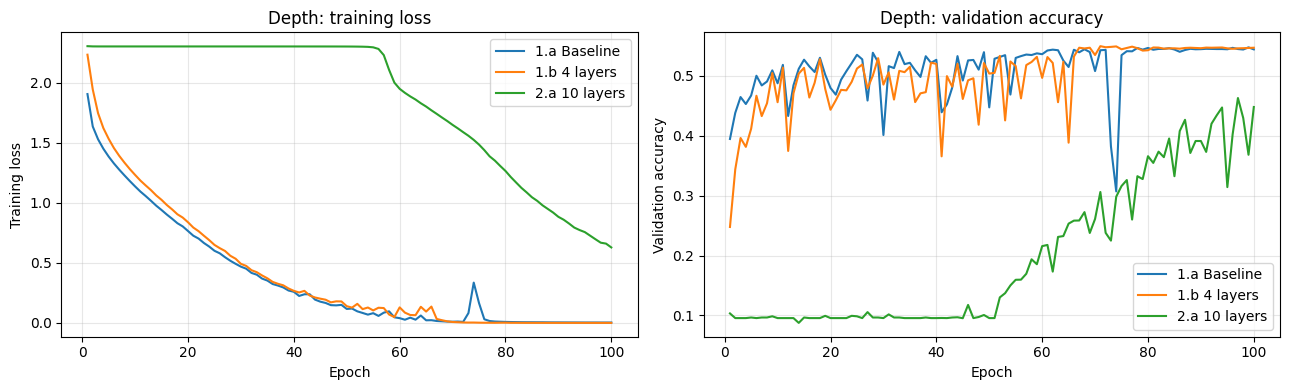

In [23]:
compare(['1.b 4 layers', '2.a 10 layers'])
plot_compare(['1.a Baseline', '1.b 4 layers', '2.a 10 layers'], 'Depth')

## 2.b Width and activation function experiments (all based on the 1.a network)

Exp 1 (wide) | epoch   1 | train loss 1.8813 acc 0.3411 | val loss 1.7041 acc 0.3992 | 1.2s
Exp 1 (wide) | epoch  10 | train loss 1.0922 acc 0.6220 | val loss 1.4549 acc 0.4972 | 11.2s
Exp 1 (wide) | epoch  20 | train loss 0.6608 acc 0.7787 | val loss 2.6027 acc 0.4488 | 22.3s
Exp 1 (wide) | epoch  30 | train loss 0.3392 acc 0.8934 | val loss 2.2161 acc 0.4958 | 33.3s
Exp 1 (wide) | epoch  40 | train loss 0.1370 acc 0.9638 | val loss 2.4933 acc 0.5158 | 44.4s
Exp 1 (wide) | epoch  50 | train loss 0.0664 acc 0.9881 | val loss 2.8050 acc 0.5202 | 55.7s
Exp 1 (wide) | epoch  60 | train loss 0.0590 acc 0.9891 | val loss 2.5544 acc 0.5552 | 66.7s
Exp 1 (wide) | epoch  70 | train loss 0.0056 acc 1.0000 | val loss 2.8092 acc 0.5472 | 77.9s
Exp 1 (wide) | epoch  80 | train loss 0.0038 acc 1.0000 | val loss 2.8637 acc 0.5582 | 88.8s
Exp 1 (wide) | epoch  90 | train loss 0.0027 acc 1.0000 | val loss 2.9501 acc 0.5550 | 100.0s
Exp 1 (wide) | epoch 100 | train loss 0.0022 acc 1.0000 | val loss 3.0

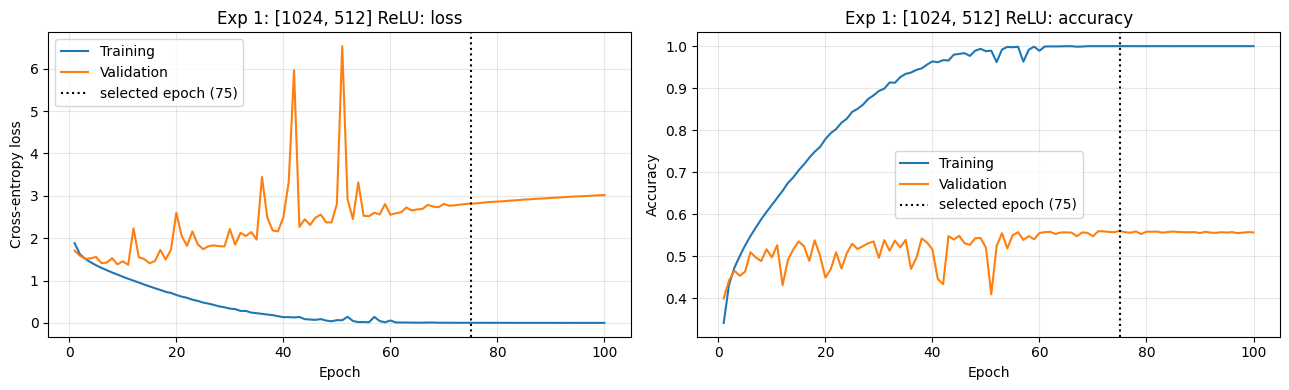

In [24]:
_, histories['Exp 1: Wide'], results['Exp 1: Wide'] = run('Exp 1 (wide)', [1024, 512])
plot_hist(histories['Exp 1: Wide'], results['Exp 1: Wide'], 'Exp 1: [1024, 512] ReLU')

Exp 2 (sigmoid) | epoch   1 | train loss 2.2731 acc 0.1628 | val loss 2.2291 acc 0.1856 | 1.0s
Exp 2 (sigmoid) | epoch  10 | train loss 1.8280 acc 0.3498 | val loss 1.8382 acc 0.3526 | 10.3s
Exp 2 (sigmoid) | epoch  20 | train loss 1.7137 acc 0.3958 | val loss 1.7298 acc 0.3916 | 20.5s
Exp 2 (sigmoid) | epoch  30 | train loss 1.6392 acc 0.4250 | val loss 1.6553 acc 0.4218 | 30.8s
Exp 2 (sigmoid) | epoch  40 | train loss 1.5762 acc 0.4496 | val loss 1.6043 acc 0.4438 | 41.2s
Exp 2 (sigmoid) | epoch  50 | train loss 1.5099 acc 0.4714 | val loss 1.5779 acc 0.4516 | 51.1s
Exp 2 (sigmoid) | epoch  60 | train loss 1.4423 acc 0.4978 | val loss 1.5309 acc 0.4726 | 61.6s
Exp 2 (sigmoid) | epoch  70 | train loss 1.3704 acc 0.5229 | val loss 1.5016 acc 0.4788 | 71.8s
Exp 2 (sigmoid) | epoch  80 | train loss 1.2902 acc 0.5529 | val loss 1.4711 acc 0.4904 | 82.2s
Exp 2 (sigmoid) | epoch  90 | train loss 1.2014 acc 0.5853 | val loss 1.4622 acc 0.4976 | 92.8s
Exp 2 (sigmoid) | epoch 100 | train loss 

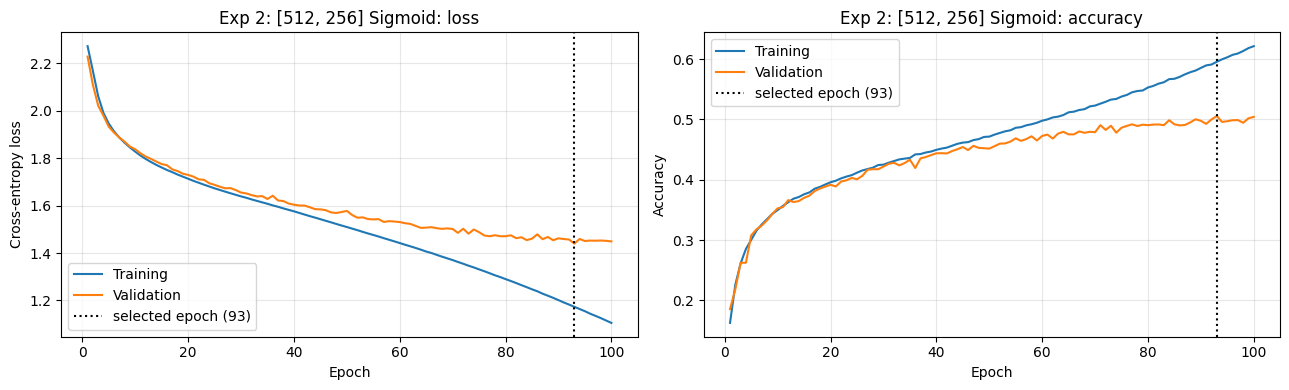

In [25]:
_, histories['Exp 2: Sigmoid'], results['Exp 2: Sigmoid'] = run('Exp 2 (sigmoid)', [512, 256], nn.Sigmoid)
plot_hist(histories['Exp 2: Sigmoid'], results['Exp 2: Sigmoid'], 'Exp 2: [512, 256] Sigmoid')

Exp 3 (tanh) | epoch   1 | train loss 1.8810 acc 0.3485 | val loss 1.7810 acc 0.3842 | 1.2s
Exp 3 (tanh) | epoch  10 | train loss 1.4144 acc 0.5191 | val loss 1.6737 acc 0.4338 | 10.3s
Exp 3 (tanh) | epoch  20 | train loss 1.0157 acc 0.6589 | val loss 1.7545 acc 0.4432 | 20.5s
Exp 3 (tanh) | epoch  30 | train loss 0.6007 acc 0.8063 | val loss 2.3774 acc 0.4072 | 30.6s
Exp 3 (tanh) | epoch  40 | train loss 0.2919 acc 0.9169 | val loss 2.9535 acc 0.4176 | 40.8s
Exp 3 (tanh) | epoch  50 | train loss 0.1213 acc 0.9731 | val loss 3.0000 acc 0.4340 | 50.9s
Exp 3 (tanh) | epoch  60 | train loss 0.0380 acc 0.9961 | val loss 3.1879 acc 0.4524 | 61.1s
Exp 3 (tanh) | epoch  70 | train loss 0.0133 acc 0.9995 | val loss 4.3777 acc 0.4036 | 71.3s
Exp 3 (tanh) | epoch  80 | train loss 0.0077 acc 1.0000 | val loss 3.5228 acc 0.4616 | 81.7s
Exp 3 (tanh) | epoch  90 | train loss 0.0055 acc 1.0000 | val loss 3.6342 acc 0.4566 | 92.1s
Exp 3 (tanh) | epoch 100 | train loss 0.0046 acc 0.9999 | val loss 3.72

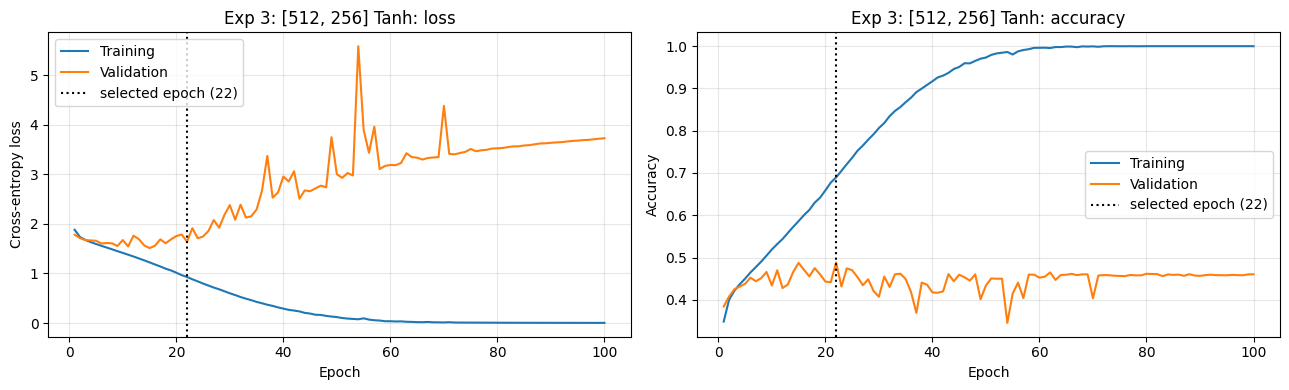

In [26]:
_, histories['Exp 3: Tanh'], results['Exp 3: Tanh'] = run('Exp 3 (tanh)', [512, 256], nn.Tanh)
plot_hist(histories['Exp 3: Tanh'], results['Exp 3: Tanh'], 'Exp 3: [512, 256] Tanh')

               Hidden layers Activation Parameters Epochs selected Training time (s) Time for 100 epochs (s) Training loss Training acc Validation acc Evaluation (test) acc
1.a Baseline      [512, 256]       ReLU    1707274              99          103.6403                104.6501        0.0032       1.0000         0.5478                0.5391
Exp 1: Wide      [1024, 512]       ReLU    3676682              75           83.2893                111.0619        0.0043       1.0000         0.5604                0.5542
Exp 2: Sigmoid    [512, 256]    Sigmoid    1707274              93           95.7788                102.8180        1.1540       0.6039         0.5056                0.4954
Exp 3: Tanh       [512, 256]       Tanh    1707274              22           22.3980                102.4129        0.8953       0.7007         0.4884                0.4767


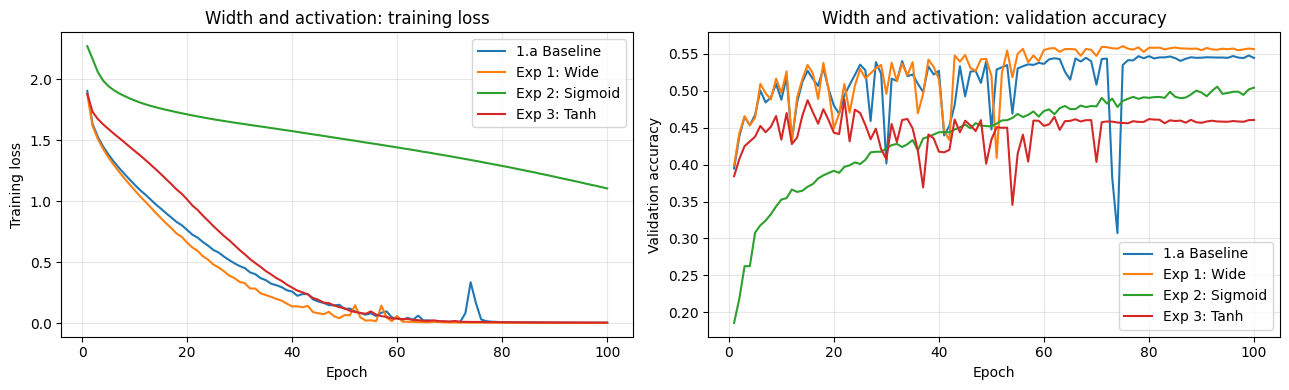

In [27]:
compare(['1.a Baseline', 'Exp 1: Wide', 'Exp 2: Sigmoid', 'Exp 3: Tanh'])
plot_compare(['1.a Baseline', 'Exp 1: Wide', 'Exp 2: Sigmoid', 'Exp 3: Tanh'], 'Width and activation')

## Summary of all experiments

                                              Hidden layers Activation Parameters Epochs selected Training time (s) Time for 100 epochs (s) Training loss Training acc Validation acc Evaluation (test) acc
1.a Baseline                                     [512, 256]       ReLU    1707274              99          103.6403                104.6501        0.0032       1.0000         0.5478                0.5391
1.b 4 layers                            [512, 256, 128, 64]       ReLU    1746506              71           92.2853                129.9383        0.0034       0.9997         0.5498                0.5442
2.a 10 layers   [512, 256, 128, 64, 64, 64, 64, 64, 64, 64]       ReLU    1771466              97          199.4631                205.2347        0.6632       0.7291         0.4632                0.4537
Exp 1: Wide                                     [1024, 512]       ReLU    3676682              75           83.2893                111.0619        0.0043       1.0000         0.5604   

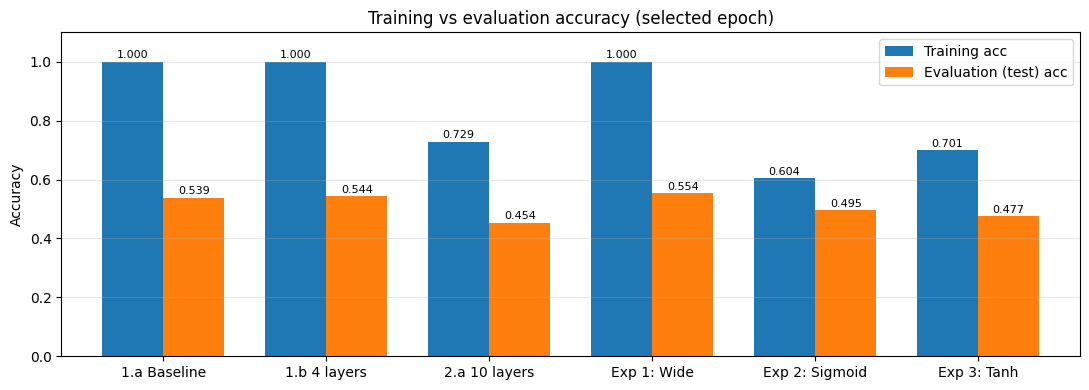

In [28]:
compare(list(results.keys()))
summary = pd.DataFrame(results).T
ax = summary[['Training acc', 'Evaluation (test) acc']].astype(float).plot(kind='bar', figsize=(11, 4), width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=8, padding=1)
ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1.1); ax.set_title('Training vs evaluation accuracy (selected epoch)')
plt.xticks(rotation=0); plt.grid(alpha=0.3, axis='y'); plt.tight_layout(); plt.show()